Introduction
============

This is an interactive worksheet for "Introduction to path planning" (Author: Björn Hein).

Version | Author
------------ | -------------
0.2 | Björn Hein


License is based on Creative Commons: Attribution-NonCommercial 4.0 International (CC BY-NC 4.0) (please check: http://creativecommons.org/licenses/by-nc/4.0/)

This worksheet contains a second draft implementation of the A* algorithm for path planning applications in Python. It follows the slides "A* - Algorithm for path planning": discretisation of the C-space, the A* algorithm, heuristics, the heuristic weight and reopening. At the end it shows the effect of the step sizes of the discretisation.

Important links are:

* General Info: http://www.python.org
* Python tutorial http://www.python.org/doc/tut/
* NetworkX http://networkx.github.io/
* NumPy and SciPy Guide http://docs.scipy.org/
* Matplotlib gallery http://matplotlib.sourceforge.net/gallery.html


Remember that:

* you have to press ctrl-return or shift-return, to execute the code in the code sections, only then the variables are "generated" and can be used
* you can execute the whole notebook by Cell->runAll

Discretisation of C-space
=========================

To use A* as path planning algorithm, the C-space must be discretised: it becomes a grid on which A* can "take place". Every grid point corresponds to exactly one configuration.

* Joint $i$: limits $\Theta_{\min,i} \dots \Theta_{\max,i}$, step size $\Delta\Theta_i$
* Grid coordinate $x_i \in \{0, 1, \dots, N_i - 1\}$ with $N_i = \frac{\Theta_{\max,i} - \Theta_{\min,i}}{\Delta\Theta_i} + 1$
* Grid point → configuration: $\varphi_i = \Theta_{\min,i} + \Delta\Theta_i\, x_i$
* Configuration → grid point: $x_i = \left\lfloor \frac{\varphi_i - \Theta_{\min,i}}{\Delta\Theta_i} + \frac{1}{2} \right\rfloor$

The example with two joints from the slides:

| Joint $i$ | $\Theta_{\min,i}$ | $\Theta_{\max,i}$ | $\Delta\Theta_i$ | $N_i$ |
| :-------: | ----------------: | ----------------: | ---------------: | ----: |
| 1         |              −90° |               90° |              20° |    10 |
| 2         |                0° |              135° |              15° |    10 |

In [134]:
import math


def toConfiguration(x, thetaMin, deltaTheta):
    """Grid point -> configuration: phi_i = thetaMin_i + deltaTheta_i * x_i"""
    return [tMin + d * xi for xi, tMin, d in zip(x, thetaMin, deltaTheta)]


def toGrid(phi, thetaMin, deltaTheta):
    """Configuration -> grid point: x_i = floor((phi_i - thetaMin_i) / deltaTheta_i + 1/2)"""
    return [math.floor((p - tMin) / d + 0.5) for p, tMin, d in zip(phi, thetaMin, deltaTheta)]


thetaMin = [-90, 0]
thetaMax = [90, 135]
deltaTheta = [20, 15]

N = [int((tMax - tMin) / d) + 1 for tMin, tMax, d in zip(thetaMin, thetaMax, deltaTheta)]
print("N =", N)
print("grid point x = (5, 2)          -> configuration", toConfiguration([5, 2], thetaMin, deltaTheta))
x = toGrid([45, 50], thetaMin, deltaTheta)
print("configuration phi = (45°, 50°) -> grid point", x, "=", toConfiguration(x, thetaMin, deltaTheta))

N = [10, 10]
grid point x = (5, 2)          -> configuration [10, 30]
configuration phi = (45°, 50°) -> grid point [7, 3] = [50, 45]


### Grid coordinates: why + ½?

Joint 1 and the configuration $\varphi_1 = 45°$: $\frac{45° + 90°}{20°} = 6.75$, the configuration lies **between** grid points 6 and 7.

* **Without** $+\frac{1}{2}$ the grid point covers the range **above** it: $\lfloor 6.75 \rfloor = 6$ → 30°, 15° away.
* **With** $+\frac{1}{2}$ the grid point covers the range **around** it (its field): $\lfloor 6.75 + 0.5 \rfloor = 7$ → 50°, 5° away. The error is at most $\frac{\Delta\Theta_i}{2}$.

Python's `round()` is no replacement: it rounds 6.5 to 6 (half to even).

In [135]:
for phi in [45, 30, 39, 41]:
    value = (phi - thetaMin[0]) / deltaTheta[0]
    without, withHalf = math.floor(value), math.floor(value + 0.5)
    print(f"phi = {phi}°: {value:.2f} -> without + 1/2: x = {without} ({toConfiguration([without], thetaMin, deltaTheta)[0]}°), "
          f"with + 1/2: x = {withHalf} ({toConfiguration([withHalf], thetaMin, deltaTheta)[0]}°)")

phi = 45°: 6.75 -> without + 1/2: x = 6 (30°), with + 1/2: x = 7 (50°)
phi = 30°: 6.00 -> without + 1/2: x = 6 (30°), with + 1/2: x = 6 (30°)
phi = 39°: 6.45 -> without + 1/2: x = 6 (30°), with + 1/2: x = 6 (30°)
phi = 41°: 6.55 -> without + 1/2: x = 6 (30°), with + 1/2: x = 7 (50°)


Calculating the hash value for nodes needed for the closed list
====================================

As the closed list of the $A^*$ algorithm is typically implemented via a *hash map*, an appropriate hash function has to be provided to identify nodes. On the slides it is the `tHashtable` CLOSED. A suitable key is based on the grid coordinates $x$ of the nodes: every grid point corresponds to exactly one configuration, and integer coordinates are exact (with floating point numbers e.g. `0.1 + 0.2 != 0.3`).

In [136]:
def getNodeID(x):
    """Compute a unique identifier based on the grid coordinates"""
    nodeId = "-"
    for i in x:
        nodeId += str(i)+"-"
    return nodeId

In [137]:
getNodeID([20,20])

'-20-20-'

In [138]:
a = dict()
a[getNodeID([20,20])] = 99
a[getNodeID([31,30])] = 101

print(a[getNodeID([31,30])], getNodeID([31,30]))
print(a[getNodeID([20,20])])

101 -31-30-
99


A*
==

In the following there is an example for programming an A*-like path planning algorithm with some modifications. Please check the slides "A* - Algorithm for path planning". The pseudocode of the slides in `IPAStar.py`:

| Slides | IPAStar.py |
| ------ | ---------- |
| `init (OPEN; CLOSED; S)` | `planPath`: reset, `_addGraphNode` for the grid point of the start |
| `n = best (OPEN)` | `_getBestNodeName`: `heapq` sorted by $f$ from `_evaluateNode` |
| `n == G` | the name of `n` is the name of the grid point of the goal |
| collision check | `pointInCollision`, when `n` is taken from OPEN: collisions are only detected then |
| `expandNode (n)` and `handleSuccessors (OPEN; CLOSED; s)` | merged to one function `_handleNode`: neighbours $x_i \pm 1$, no reopening |
| `printSolution (…)` | `_collectPath`: follows the fathers from G back to S |
| OPEN (`tHeap`), CLOSED (`tHashtable`) | `self.openList` (`heapq`), `self.graph` (`networkx.DiGraph`, key from `_getNodeID`) |

In [139]:
from IPAStar import AStar
from IPVISAStar import aStarVisualize
import matplotlib.pylab as plt
import IPTestSuite as ts

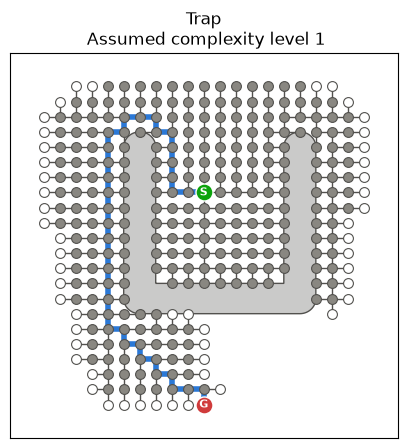

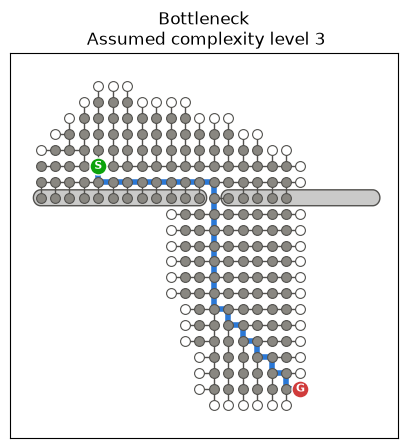

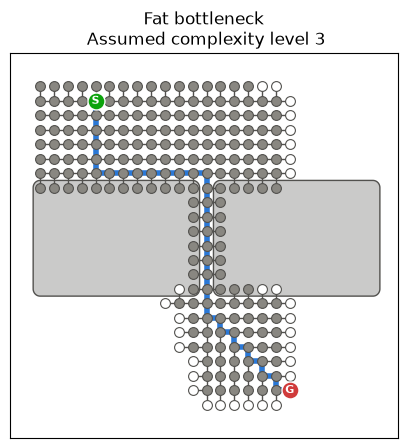

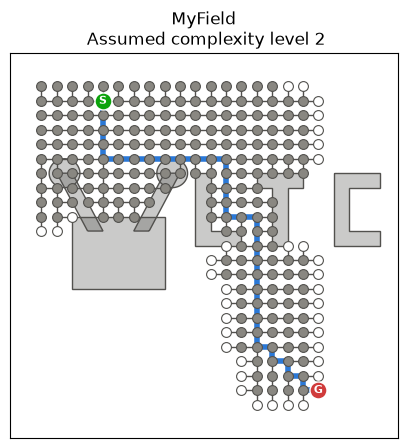

In [140]:
astarConfig = dict()
astarConfig["w"] = .5
astarConfig["heuristic"]  = "euclidean"

for benchmark in ts.benchList:
    try:
        fig_local = plt.figure(figsize=(5,5))
        ax = fig_local.add_subplot(1,1,1)
        astar = AStar(benchmark.collisionChecker)
        solution = astar.planPath(benchmark.startList, benchmark.goalList, astarConfig)
        title = benchmark.name
        if not solution:
            title += " (No path found!)"
        title += "\n Assumed complexity level " + str(benchmark.level)
        ax.set_title(title)
        aStarVisualize(astar, solution, ax=ax, nodeSize=50)
    except Exception as e:
        print("ERROR: ",benchmark.name, e)

Questions:

* What could be useful to be checked in function setStartGoal besides start and goal having the same dimension?
* What is missing for a correct implementation of the A*? 
  * Why does this version not necessarily find the best solution? 
  * Why is it nevertheless useful to do so?

**Antworten:**

* **Prüfungen für Start & Ziel:** Es sollte zusätzlich geprüft werden, ob die Dimension zum `CollisionChecker` passt und ob Start und Ziel **innerhalb der Raumgrenzen** sowie **kollisionsfrei** sind (das macht in dieser Version bereits `_checkStartGoal`).
* **Was für korrekten A\* fehlt:** Das Aktualisieren bzw. erneute Öffnen bereits besuchter Knoten (**Updates in `OPEN` & Reopening aus `CLOSED`**), sobald ein günstigerer Weg zu ihnen gefunden wird.
  * *Warum nicht immer optimal:* Ohne diese Korrektur bleibt der zuerst gefundene Pfad zu einem Knoten bestehen – auch wenn es später einen kürzeren Weg dorthin gibt.
  * *Warum trotzdem nützlich:* Jeder Knoten wird höchstens einmal bearbeitet. Das spart Rechenzeit und Verwaltungsaufwand (Heap-Updates / erneutes Expandieren ganzer Teilbäume).


### Do the planning

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

from shapely.geometry import Point, Polygon, LineString
from IPEnvironment import CollisionChecker

# Testumgebung definieren: U-förmige Falle (Linienzug mit Radius 1.0 gebuffert)
trapField = dict()
trapField["obs1"] =   LineString([(6, 18), (6, 8), (16, 8), (16,18)]).buffer(1.0)

# CollisionChecker prüft später im A*, ob Gitterpunkte innerhalb der Grenzen und kollisionsfrei sind
environment = CollisionChecker(trapField)

# Start- und Zielkonfiguration (als Liste von Punkten, passend zur BaseClass)
start = [[10,20]]
goal  = [[13,1]]

astar = AStar(environment)

# Konfiguration für planPath
# w = 0.5 -> klassischer A* (gleiche Gewichtung von bisherigen Kosten g und Heuristik h)
# heuristic = "euclidean" -> euklidische Distanz (Luftlinie) auf dem Gitter als Schätzwert h
astarConfig = dict()
astarConfig["w"] = .5
astarConfig["heuristic"]  = "euclidean"

# Pfadplanung starten; Rückgabe ist eine Liste der Knoten-IDs von Start bis Ziel (oder None)
solution = astar.planPath(start, goal, astarConfig )


solution =  ['-10-20-', '-11-20-', '-12-20-', '-13-20-', '-14-20-', '-15-20-', '-16-20-', '-17-20-', '-17-19-', '-18-19-', '-18-18-', '-18-17-', '-18-16-', '-18-15-', '-18-14-', '-18-13-', '-18-12-', '-18-11-', '-18-10-', '-18-9-', '-18-8-', '-18-7-', '-18-6-', '-17-6-', '-17-5-', '-16-5-', '-16-4-', '-15-4-', '-15-3-', '-14-3-', '-14-2-', '-13-2-', '-13-1-']


### Do the visualization

* Idea: Show internal data of AStar
* show closeList and the evaluated values for these nodes
* add these information in a matrix

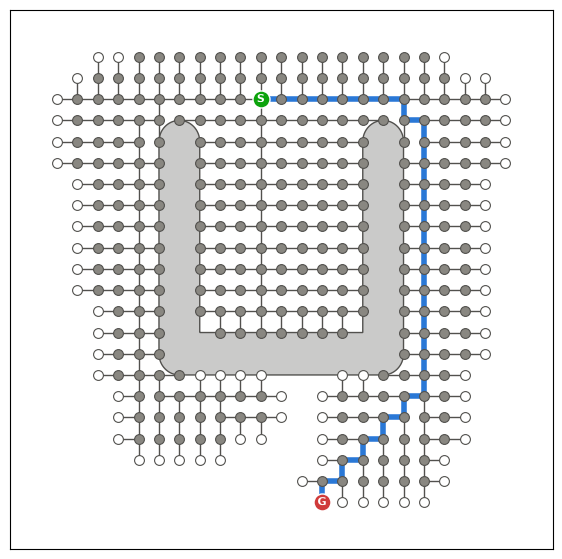

In [142]:
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(1,1,1)
aStarVisualize(astar, solution, ax = ax, nodeSize=50)

Comparison: used metrics
========================

The trap example from above with $w = 0.5$, once with the Manhattan and once with the Euclidean distance as heuristic. The numbers are the same as on the slides: closed nodes, nodes in collision and edges of the path.

In [143]:
import numpy as np
from scipy.spatial.distance import euclidean


def statistics(planner, solution):
    """Closed nodes, nodes in collision, reopenings and updates in OPEN, edges and length of the path"""
    # Alle besuchten Knoten (mit ihren Attributen) aus dem Suchgraphen holen
    nodes = planner.graph.nodes(data=True)
    # Kennzahlen über den Suchaufwand sammeln (expandierte Knoten, Kollisionen, Reopenings/Updates)
    result = {"closed": sum(1 for _, data in nodes if data["status"] == "closed"),
              "in collision": sum(1 for _, data in nodes if data.get("collision") == 1),
              "reopened": sum(data.get("reopened", 0) for _, data in nodes),
              "updated": sum(data.get("updated", 0) for _, data in nodes),
              "edges": None, "length": None}
    if solution:
        # Reale Konfigurationen (pos) entlang des Lösungspfads auslesen und Kantenanzahl + Pfadlänge berechnen
        points = [planner.graph.nodes[node]["pos"] for node in solution]
        result["edges"] = len(solution) - 1
        result["length"] = sum(euclidean(p, q) for p, q in zip(points, points[1:]))
    return result


def planAndShow(collisionChecker, startList, goalList, runs, panelSize=5):
    """Plan once for every (title, config) in runs and draw the results side by side.
    config completes the base configuration w = 0.5, heuristic "euclidean"."""
    # Für jeden Eintrag in runs einen eigenen Subplot nebeneinander anlegen
    fig, axes = plt.subplots(1, len(runs), figsize=(panelSize * len(runs), panelSize + 0.6))
    limits = collisionChecker.getEnvironmentLimits()
    for ax, (title, config) in zip(np.atleast_1d(axes), runs):
        # Standard-Config (w=0.5, euclidean) mit den übergebenen Optionen überschreiben
        config = {"w": 0.5, "heuristic": "euclidean", **config}
        astar = AStar(collisionChecker)
        solution = astar.planPath(startList, goalList, config)
        result = statistics(astar, solution)
        # Kennzahlen direkt im Titel des jeweiligen Subplots anzeigen
        title += f"\nclosed: {result['closed']} · in collision: {result['in collision']}"
        title += f"\npath: {result['edges']} edges, length {result['length']:.1f}" if solution else "\nno path found!"
        if config.get("reopening"):
            title += f"\nreopenings: {result['reopened']} · updates in OPEN: {result['updated']}"
        ax.set_title(title)
        # the size of the nodes follows the smallest step size
        step = min(np.atleast_1d(config.get("discretization", 1)))
        # Suchgraph (OPEN/CLOSED) und Lösungspfad im Subplot zeichnen
        aStarVisualize(astar, solution, ax=ax, nodeSize=min((1.6 * panelSize * step)**2, 300))
        ax.set_xlim(limits[0][0] - 0.5, limits[0][1] + 0.5)
        ax.set_ylim(limits[1][0] - 0.5, limits[1][1] + 0.5)
        ax.set_aspect("equal")
    plt.tight_layout()
    plt.show()


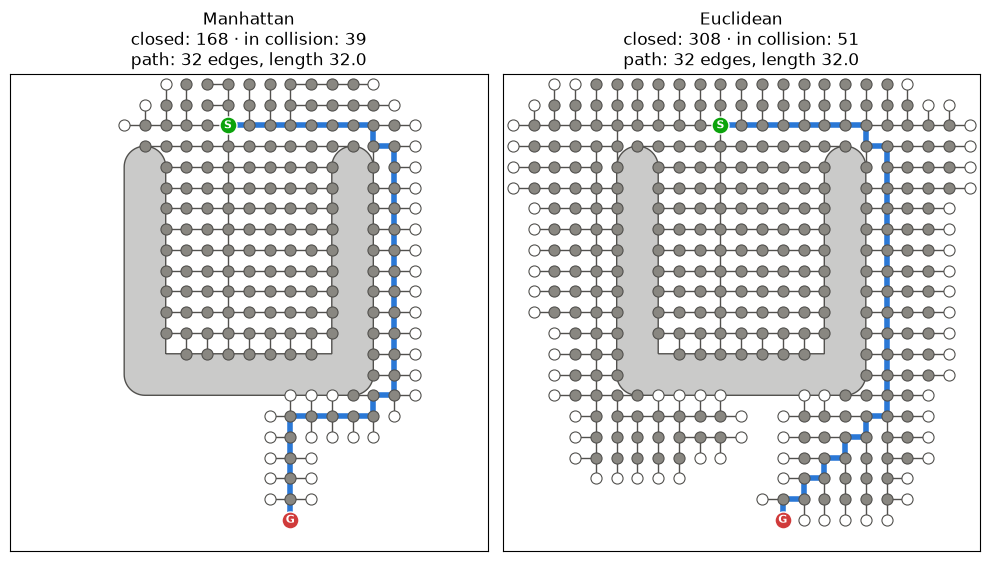

In [144]:
# Direkter Vergleich der beiden Heuristiken (Manhattan vs. Euklidisch) bei w = 0.5 auf der Trap-Umgebung
planAndShow(environment, start, goal, [("Manhattan", {"heuristic": "manhattan"}),
                                       ("Euclidean", {"heuristic": "euclidean"})])


Modifying evaluation function
=============================

Modified evaluation function: $f(n) = (1-w)\,g(n) + w\,h(n)$

* **$g(n)$:** bisherige Pfadkosten vom Start bis zum Knoten $n$ (*Vergangenheit*)
* **$h(n)$:** geschätzte Restkosten von $n$ bis zum Ziel (*Zukunft / Heuristik*)
* **$w \in [0, 1]$:** Heuristik-Gewicht – steuert das Gleichgewicht zwischen **Optimalität** und **Suchgeschwindigkeit**:

| Gewicht $w$ | Algorithmus | Verhalten |
| :--- | :--- | :--- |
| **$w = 0$** | **Dijkstra** ($f(n) = g(n)$) | Ignoriert die Zielrichtung komplett; breitet sich gleichmäßig in alle Richtungen aus $\rightarrow$ **garantiert optimaler Pfad**, aber **sehr viele expandierte Knoten**. |
| **$w = 0{,}5$** | **Klassischer A\*** ($g$ und $h$ gleich gewichtet) | Guter Kompromiss aus Kosten und Zielrichtung $\rightarrow$ **optimal** (bei zulässiger Heuristik) und deutlich **weniger Knoten** als Dijkstra. |
| **$0{,}5 < w < 1$** | **Weighted A\*** | Bevorzugt die Heuristik stärker $\rightarrow$ oft **schneller**, verliert aber die Optimalitätsgarantie (Pfad kann länger werden). |
| **$w = 1$** | **Greedy Best-First Search** ($f(n) = h(n)$) | Ignoriert bisherige Kosten $g(n)$ und rennt blind Richtung Ziel $\rightarrow$ **sehr schnell**, bleibt aber in **Fallen (Trap)** leicht hängen bzw. findet dort **suboptimale (längere) Pfade**. |


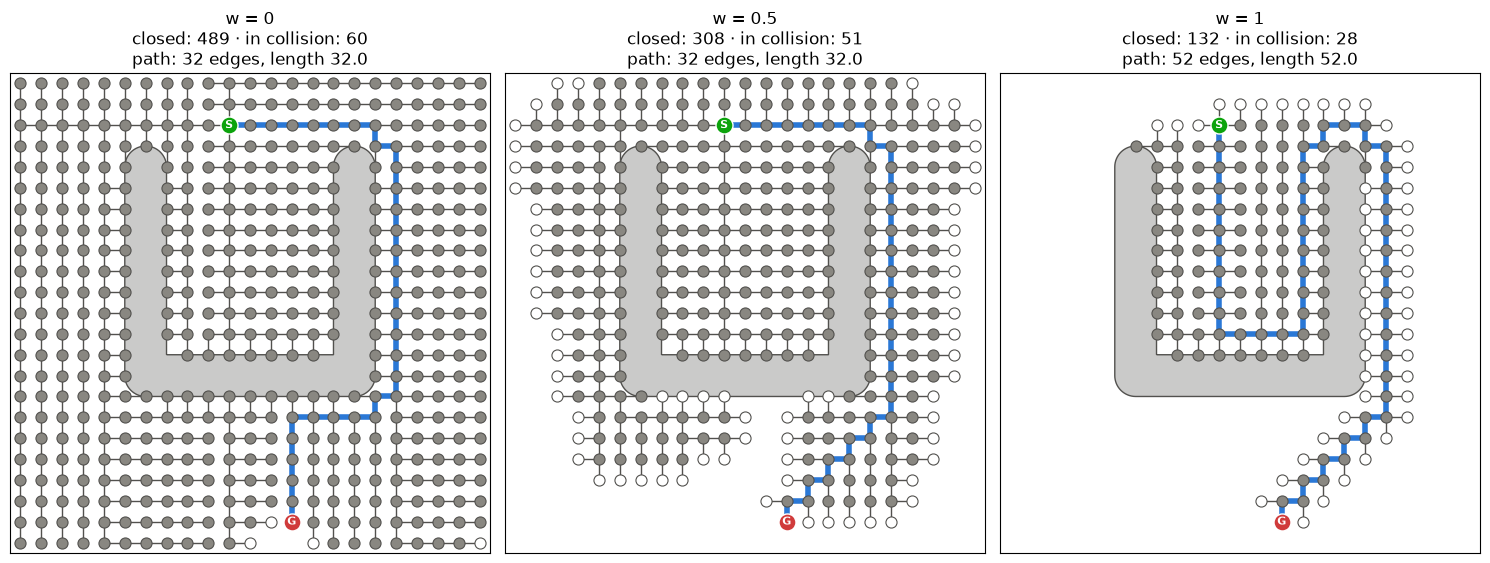

In [ ]:
# Vergleich der Gewichtung w = 0, 0.5, 1 bei euklidischer Heuristik
# w = 0: keine Heuristik

planAndShow(environment, start, goal, [(f"w = {w}", {"w": w}) for w in [0, 0.5, 1]])

### Heuristic weight: trap example

$w$ from 0 to 1 in steps of 0.05, with both heuristics:

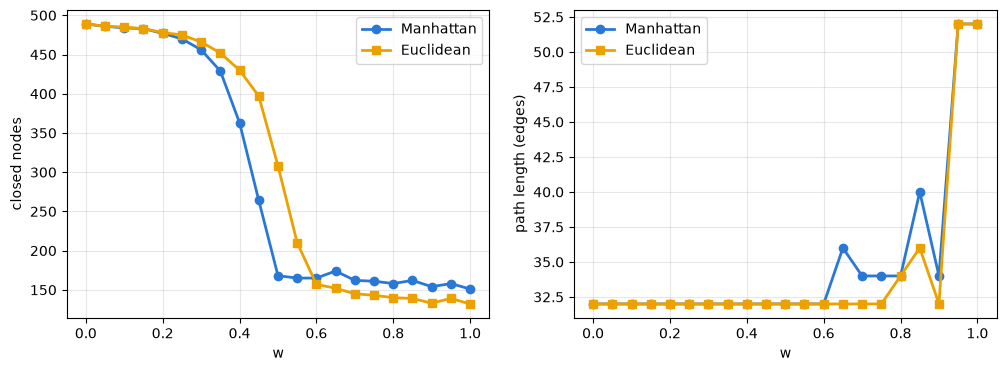

In [146]:
weights = [i / 20 for i in range(21)]
fig, (axClosed, axEdges) = plt.subplots(1, 2, figsize=(12, 4))
for heuristic, label, color, marker in [("manhattan", "Manhattan", "#2a78d6", "o"),
                                        ("euclidean", "Euclidean", "#eda100", "s")]:
    results = []
    for w in weights:
        astar = AStar(environment)
        results.append(statistics(astar, astar.planPath(start, goal, {"w": w, "heuristic": heuristic})))
    axClosed.plot(weights, [r["closed"] for r in results], color=color, marker=marker, lw=2, ms=6, label=label)
    axEdges.plot(weights, [r["edges"] for r in results], color=color, marker=marker, lw=2, ms=6, label=label)
for ax, ylabel in [(axClosed, "closed nodes"), (axEdges, "path length (edges)")]:
    ax.set(xlabel="w", ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

**Ergebnis (Trap-Beispiel):**

* **Suchaufwand (`closed nodes`, links):** Bei $w = 0$ (Dijkstra) werden fast alle freien Knoten expandiert (`489`). Mit steigendem $w$ sinkt der Aufwand stark ab (bis auf `132–151` bei $w = 1$). Bis $w = 0{,}55$ ist **Manhattan** deutlich sparsamer als **Euklidisch** (bei $w = 0{,}5$: `168` vs. `308` Knoten), weil Manhattan die 4er-Gitterdistanz besser schätzt.
* **Pfadlänge (`edges`, rechts):** Bis $w = 0{,}5$ bleibt der Pfad garantiert **optimal** (`32` Kanten). Ab ca. $w > 0{,}6$ bzw. $0{,}75$ verliert A\* die Optimalitätsgarantie: Er läuft erst tief in die U-Falle hinein und findet (ohne Reopening) am Ende deutlich längere Umwege (bis zu `52` Kanten bei $w = 0{,}95\text{–}1{,}0$).


Reopening
=========

`handleSuccessors` on the slides: what happens, if a successor $s'$ is already in OPEN or CLOSED?

* **Without reopening** (default of `IPAStar`): $s'$ is skipped, the first path to a node is kept.
* **With reopening** (`astarConfig["reopening"] = True`): if the new path is cheaper, $s'$ gets the new father and the lower $g$ and goes (back) into OPEN. A node in OPEN gets a better place in the heap, a closed node is reopened and corrects its successors, when it is expanded again.

```
procedure handleSuccessors (OPEN; CLOSED; s)
begin
    for each s' in s do begin
        g' = g(n) + c(n, s');
        if (s' ∉ OPEN ∪ CLOSED) then
            father (s') = n;  g(s') = g';  insert (OPEN; s');
        else if (g' < g(s')) then          // cheaper path found
            father (s') = n;  g(s') = g';
            if (s' ∈ CLOSED) then
                move (s'; CLOSED; OPEN);   // reopening
            else
                update (OPEN; s');         // new f(s')
            endif
        endif
    end
end;
```

In the figures nodes, that got a cheaper path while in OPEN, have a violet ring, reopened nodes are violet.

### Classic A* (w = 0.5)

A bar on a 10 x 10 grid, Manhattan distance:

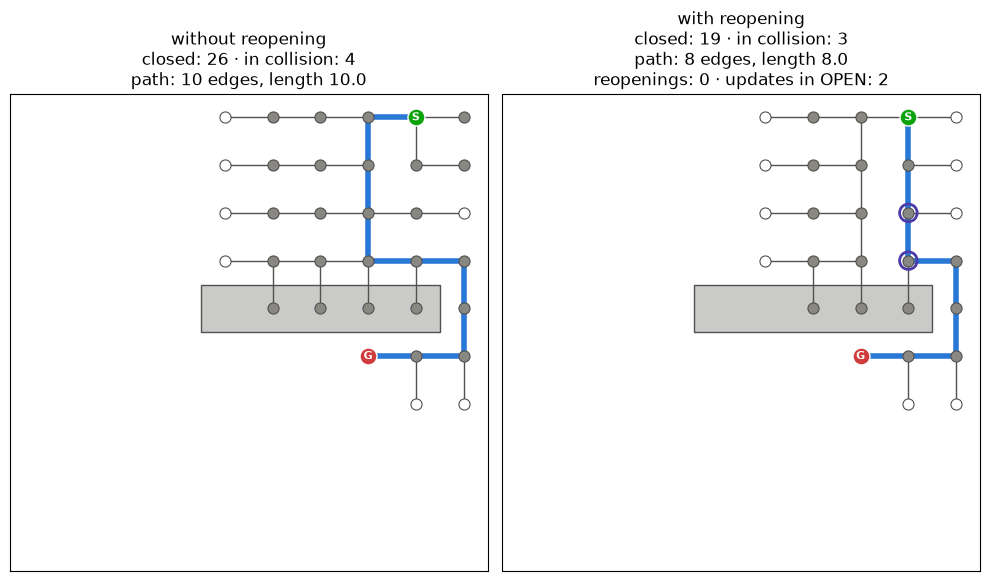

reopening False: g of the nodes below S: [1, 4, 5]
reopening True: g of the nodes below S: [1, 2, 3]


In [147]:
bar = CollisionChecker({"bar": Polygon([(3.5, 4.5), (8.5, 4.5), (8.5, 5.5), (3.5, 5.5)])}, limits=[[0, 9], [0, 9]])
barStart, barGoal = [[8, 9]], [[7, 4]]
planAndShow(bar, barStart, barGoal, [("without reopening", {"heuristic": "manhattan"}),
                                     ("with reopening", {"heuristic": "manhattan", "reopening": True})])

for reopening in [False, True]:
    astar = AStar(bar)
    astar.planPath(barStart, barGoal, {"w": 0.5, "heuristic": "manhattan", "reopening": reopening})
    g = {tuple(data["pos"]): data["g"] for _, data in astar.graph.nodes(data=True)}
    print(f"reopening {reopening}: g of the nodes below S:", [g[(8, y)] for y in [8, 7, 6]])

Without reopening the nodes below S are first reached over the detour on the left (with equal $f$ the order of the names in the heap decides), the cheaper path found later is skipped. With reopening they are updated in OPEN. The heuristic is consistent for $w \le 0.5$: closed nodes are never reopened.

### Weighted A* (w = 1)

For $w > 0.5$ the heuristic weighs more than the path costs: nodes are closed before their cheapest path is known.

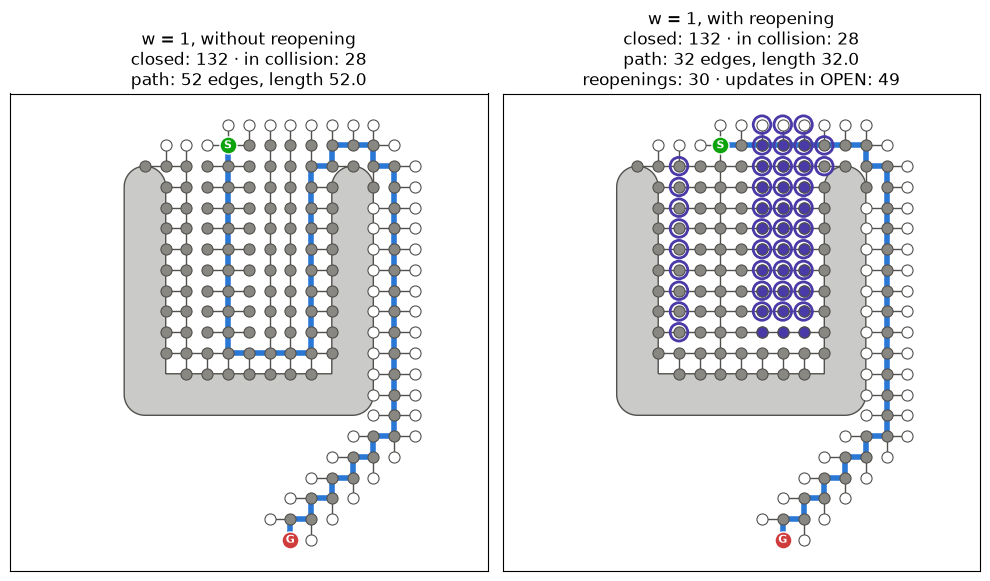

In [148]:
planAndShow(environment, start, goal, [("w = 1, without reopening", {"w": 1}),
                                       ("w = 1, with reopening", {"w": 1, "reopening": True})])

### Reopening and the heuristic weight

The trap example, $w$ from 0 to 1 in steps of 0.05:

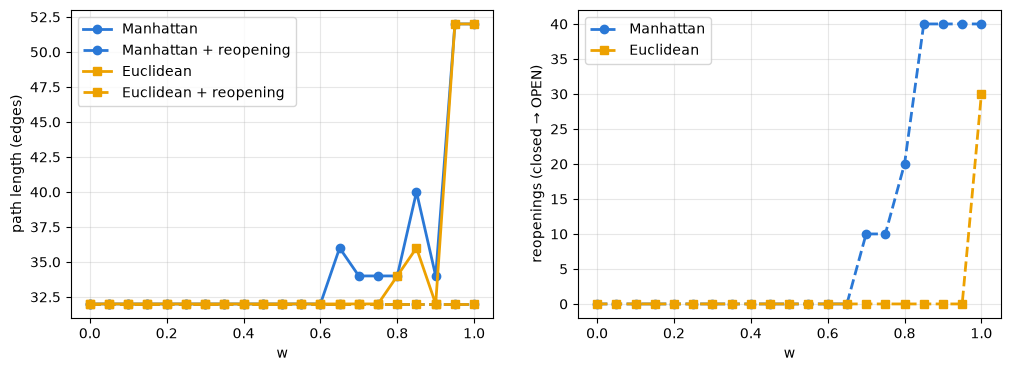

In [149]:
fig, (axEdges, axReopened) = plt.subplots(1, 2, figsize=(12, 4))
for heuristic, label, color, marker in [("manhattan", "Manhattan", "#2a78d6", "o"),
                                        ("euclidean", "Euclidean", "#eda100", "s")]:
    for reopening, style in [(False, "-"), (True, "--")]:
        results = []
        for w in weights:
            astar = AStar(environment)
            solution = astar.planPath(start, goal, {"w": w, "heuristic": heuristic, "reopening": reopening})
            results.append(statistics(astar, solution))
        name = label + (" + reopening" if reopening else "")
        axEdges.plot(weights, [r["edges"] for r in results], style, color=color, marker=marker, lw=2, ms=6, label=name)
        if reopening:
            axReopened.plot(weights, [r["reopened"] for r in results], style, color=color, marker=marker, lw=2, ms=6,
                            label=label)
for ax, ylabel in [(axEdges, "path length (edges)"), (axReopened, "reopenings (closed → OPEN)")]:
    ax.set(xlabel="w", ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

### All benchmarks

In [150]:
import pandas as pd
from IPython.display import display

rows = []
for benchmark in ts.benchList:
    for heuristic in ["manhattan", "euclidean"]:
        for w in [0.5, 0.7, 1]:
            row = {"benchmark": benchmark.name, "heuristic": heuristic, "w": w}
            for reopening in [False, True]:
                astar = AStar(benchmark.collisionChecker)
                solution = astar.planPath(benchmark.startList, benchmark.goalList,
                                          {"w": w, "heuristic": heuristic, "reopening": reopening})
                result = statistics(astar, solution)
                suffix = " (reopening)" if reopening else ""
                row["edges" + suffix] = result["edges"]
                row["closed" + suffix] = result["closed"]
            row["reopenings"], row["updates in OPEN"] = result["reopened"], result["updated"]
            rows.append(row)
display(pd.DataFrame(rows))

,benchmark,heuristic,w,edges,closed,edges (reopening),closed (reopening),reopenings,updates in OPEN
0,Trap,manhattan,0.5,36,190,36,190,0,0
1,Trap,manhattan,0.7,36,152,36,152,0,0
2,Trap,manhattan,1.0,46,150,36,150,0,5
3,Trap,euclidean,0.5,36,272,36,272,0,0
4,Trap,euclidean,0.7,38,146,36,144,0,6
5,Trap,euclidean,1.0,46,136,36,136,0,20
6,Bottleneck,manhattan,0.5,28,100,28,104,0,4
7,Bottleneck,manhattan,0.7,28,35,28,35,0,0
8,Bottleneck,manhattan,1.0,28,35,28,35,0,0
9,Bottleneck,euclidean,0.5,28,179,28,179,0,0


Questions:

* Why is no closed node reopened for $w \le 0.5$? (Hint: consistent heuristic)
* In the bar example the heuristic is consistent, but without reopening the path is longer. Which part of `handleSuccessors` does the classic A* need?
* For which benchmarks and $w$ is the path **longer** with reopening? How can that be?
* What does reopening cost?

Experiments
===========

* Implement another heuristic (e.g. the maximum norm $\max_i |x_i - x_{G,i}|$) and make it switchable via the parameter `heuristic`. Which of the heuristics never overestimate the path costs in the 4-neighbourhood?
* Use the diagonal neighbours as well (8-neighbourhood, see `_handleNode9`). Which costs should a diagonal step get, and which heuristic fits then?


### Experiment 1: Weitere Heuristik (Platzhalter)


In [151]:
# Platzhalter für Experiment 1:
# Hier könnte z. B. die Maximum-Norm (Chebyshev-Distanz: max_i |x_i - x_G,i|) als
# weitere Heuristik in einer Unterklasse oder in IPAStar.py ergänzt werden.


### Experiment 2: Diagonale Nachbarn (8er-Nachbarschaft mit `_handleNode9`)

* **Kosten eines diagonalen Schritts:** Statt pauschal `1` pro Kante wird die euklidische Schrittweite auf dem Gitter verwendet (`euclidean(parent_grid, x)`): `1` für horizontale/vertikale Schritte und $\sqrt{2} \approx 1{,}414$ für diagonale Schritte in 2D.
* **Passende Heuristik:** Die **euklidische Distanz** (oder Oktil-Distanz), da sie die tatsächlichen Kosten in der 8er-Nachbarschaft nie überschätzt (*zulässig*). Die Manhattan-Distanz hingegen wäre nicht mehr zulässig, weil ein diagonaler Schritt nur $\sqrt{2}$ statt $2$ kostet.

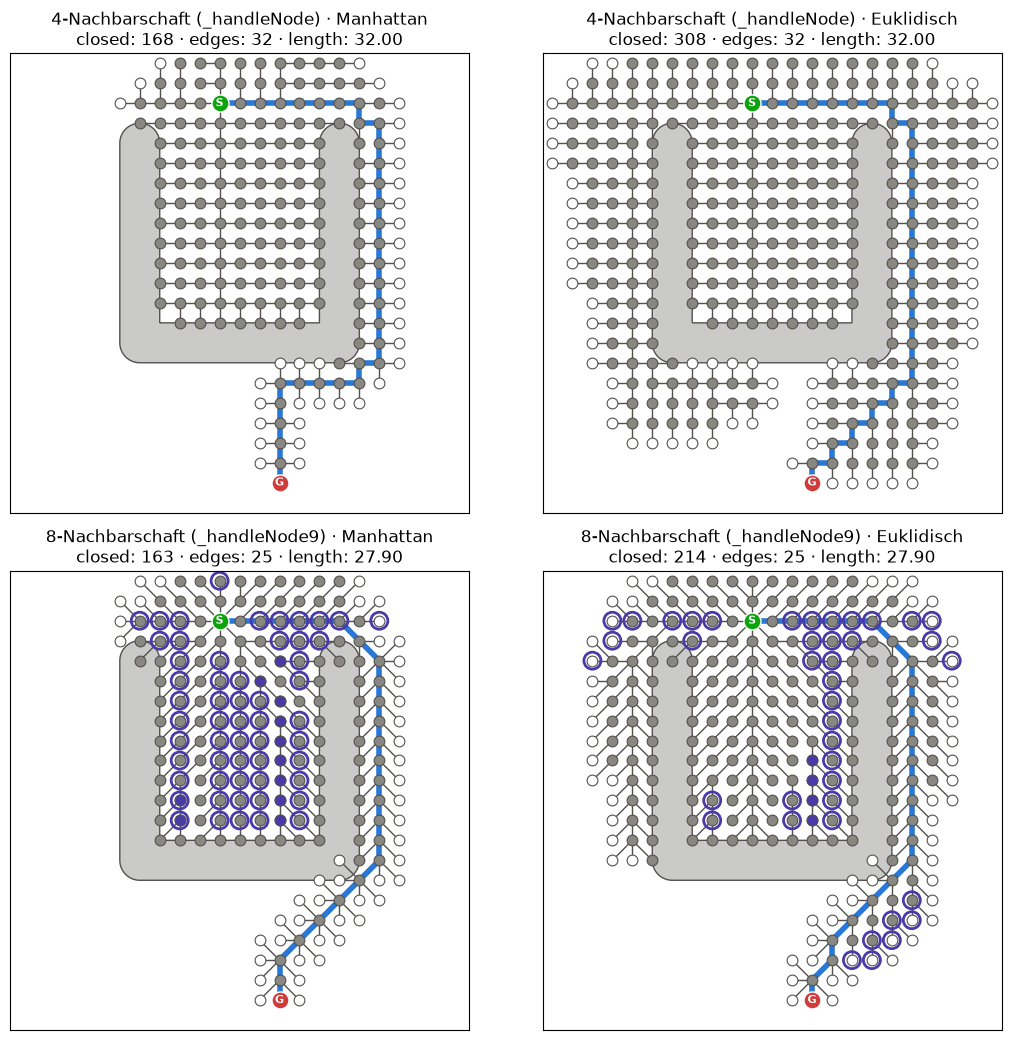

In [152]:
from IPPerfMonitor import IPPerfMonitor


class DiagonalAStar(AStar):
    """A*-Variante mit 8er-Nachbarschaft (in 2D) über _handleNode9 und euklidischen Schrittkosten."""

    @IPPerfMonitor
    def _handleNode(self, nodeName):
        # Nutzt die bereits vorbereitete Methode _handleNode9 für diagonale Nachbarn
        return self._handleNode9(nodeName)

    @IPPerfMonitor
    def _addGraphNode(self, x, pos, fatherName=None):
        nodeName = self._getNodeID(x)
        self.graph.add_node(nodeName, pos=pos, grid=x, status='open', g=0)

        if fatherName is not None:
            self.graph.add_edge(nodeName, fatherName)
            # Schrittkosten auf dem Gitter: 1 für achsenparallele, sqrt(2) für diagonale Schritte
            step_cost = euclidean(self.graph.nodes[fatherName]["grid"], x)
            self.graph.nodes[nodeName]["g"] = self.graph.nodes[fatherName]["g"] + step_cost

        self._insertNodeNameInOpenList(nodeName)

    def _reopenNode(self, nodeName, fatherName):
        node = self.graph.nodes[nodeName]
        step_cost = euclidean(self.graph.nodes[fatherName]["grid"], node["grid"])
        g = self.graph.nodes[fatherName]["g"] + step_cost
        if g >= node["g"] or node.get("collision") == 1:
            return
        self.graph.remove_edges_from(list(self.graph.out_edges(nodeName)))
        self.graph.add_edge(nodeName, fatherName)
        node["g"] = g
        if node["status"] == 'closed':
            node["status"] = 'open'
            node["reopened"] = node.get("reopened", 0) + 1
        else:
            node["updated"] = node.get("updated", 0) + 1
        self._insertNodeNameInOpenList(nodeName)


# 2x2-Vergleich: 4er- vs. 8er-Nachbarschaft × Manhattan vs. Euklidisch
fig, axes = plt.subplots(2, 2, figsize=(11, 10.5))
limits = environment.getEnvironmentLimits()

variants = [
    ("4-Nachbarschaft (_handleNode)", AStar),
    ("8-Nachbarschaft (_handleNode9)", DiagonalAStar),
]
heuristics = [
    ("Manhattan", "manhattan"),
    ("Euklidisch", "euclidean"),
]

for row_axes, (n_label, cls) in zip(axes, variants):
    for ax, (h_label, h_name) in zip(row_axes, heuristics):
        cfg = {"w": 0.5, "heuristic": h_name, "reopening": True}
        planner = cls(environment)
        sol = planner.planPath(start, goal, cfg)
        res = statistics(planner, sol)
        ax.set_title(f"{n_label} · {h_label}\nclosed: {res['closed']} · edges: {res['edges']} · length: {res['length']:.2f}")
        aStarVisualize(planner, sol, ax=ax, nodeSize=60)
        ax.set_xlim(limits[0][0] - 0.5, limits[0][1] + 0.5)
        ax.set_ylim(limits[1][0] - 0.5, limits[1][1] + 0.5)
        ax.set_aspect("equal")

plt.tight_layout()
plt.show()


Discretisation per dimension in IPAStar
=======================================

`IPAStar` discretises the C-space as on the slides (see the beginning of this worksheet): $\Theta_{\min,i}$ are the lower limits of the collision checker (`getEnvironmentLimits()`), the step sizes $\Delta\Theta_i$ are part of the configuration:

    astarConfig["discretization"] = [1.0, 0.5]   # step size per dimension, a single number for all, default: 1
    astarConfig["maxIterations"]  = 20000        # a finer grid needs more expansions, default: 1000

* A* takes place on the grid: the successors of a node are its neighbours $x_i \pm 1$, every edge costs 1 ($g$ counts the edges) and the heuristic measures the distance in grid coordinates.
* The configuration $\varphi_i = \Theta_{\min,i} + \Delta\Theta_i\, x_i$ of a node is needed for the collision check and for the path.
* Start and goal belong to the grid point of their field, $x_i = \left\lfloor \frac{\varphi_i - \Theta_{\min,i}}{\Delta\Theta_i} + \frac{1}{2} \right\rfloor$. Their nodes keep the exact configuration, so that the path starts in S and ends in G; `n == G` means: `n` is the grid point of the goal.
* With $\Delta\Theta_i = 1$ and $\Theta_{\min,i} = 0$, as in all benchmarks, grid coordinates and configurations are the same: the results above stay as they were.

### Same step size in all dimensions

The trap example with a coarser, the original and a finer discretisation:

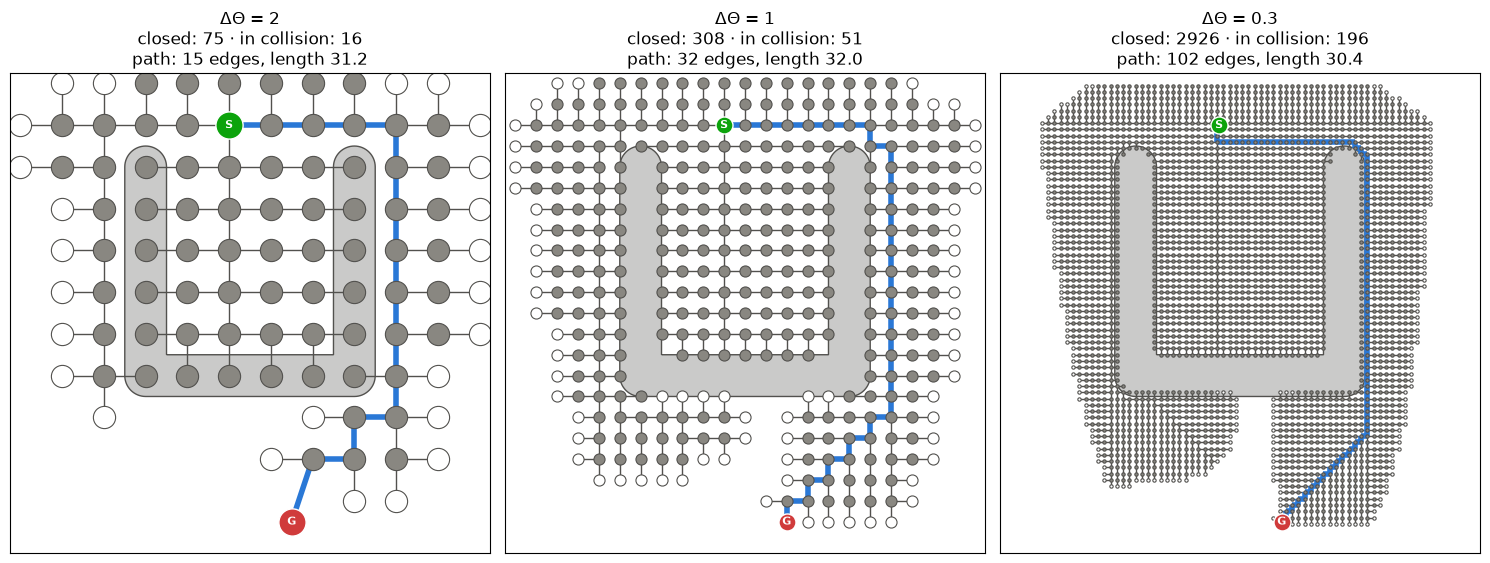

In [153]:
planAndShow(environment, start, goal, [(f"ΔΘ = {d}", {"discretization": d, "maxIterations": 20000}) for d in [2, 1, 0.3]])

### Different step sizes per dimension

Every edge costs 1, whatever the step size: different step sizes make sense when the dimensions have different units or a different effect, e.g. the joint angles of a robot. With $\Delta\Theta = (0.3, 0.7)$ start and goal do not lie on grid points.

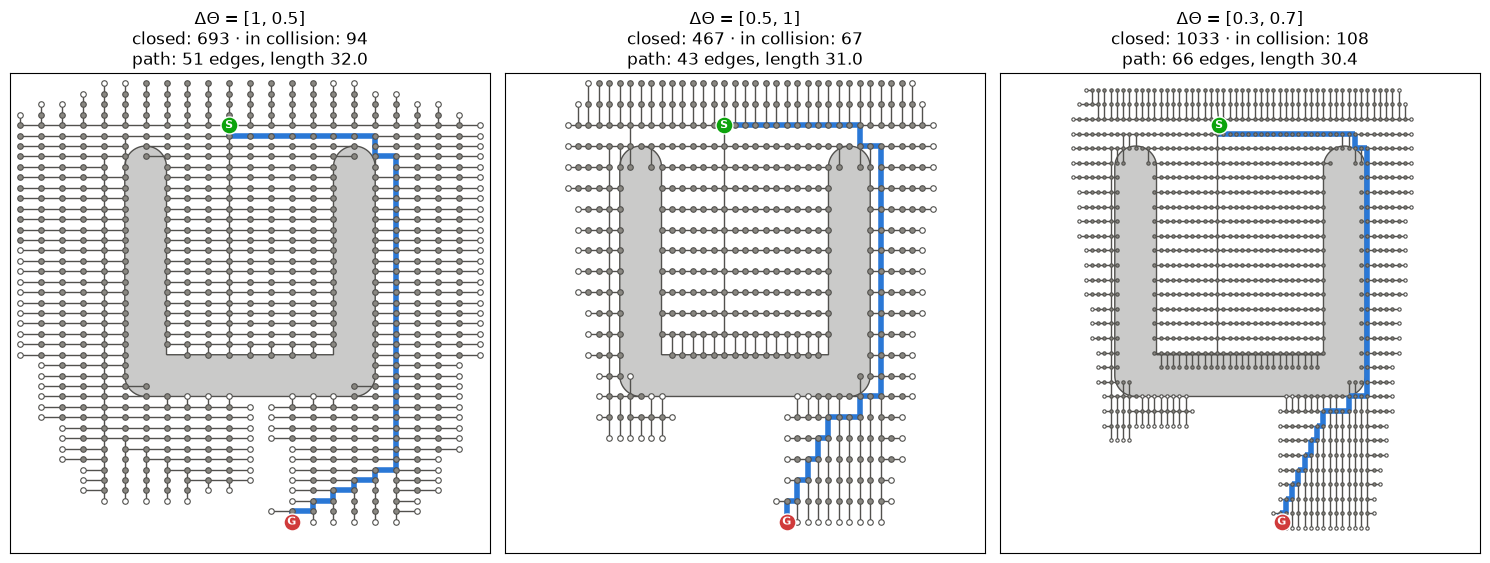

In [154]:
planAndShow(environment, start, goal, [(f"ΔΘ = {d}", {"discretization": d, "maxIterations": 20000})
                                       for d in [[1, 0.5], [0.5, 1], [0.3, 0.7]]])

### Effort and path on all benchmarks

In [155]:
import pandas as pd
from IPython.display import display

stepSizes = [2, 1, 0.5, 0.25]
rows = []
for benchmark in ts.benchList:
    for d in stepSizes:
        astar = AStar(benchmark.collisionChecker)
        solution = astar.planPath(benchmark.startList, benchmark.goalList,
                                  {"w": 0.5, "heuristic": "euclidean", "discretization": d, "maxIterations": 20000})
        result = statistics(astar, solution)
        rows.append({"benchmark": benchmark.name, "ΔΘ": d, "closed": result["closed"], "edges": result["edges"],
                     "length": round(result["length"], 1) if solution else None})
results = pd.DataFrame(rows)

for value in ["closed", "edges", "length"]:
    print(value)
    display(results.pivot(index="benchmark", columns="ΔΘ", values=value)[stepSizes])

closed


ΔΘ,2.00,1.00,0.50,0.25
benchmark,,,,
Bottleneck,71,179,690,2780
Fat bottleneck,63,212,741,2893
MyField,61,216,873,4262
Trap,77,272,951,3477


edges


ΔΘ,2.00,1.00,0.50,0.25
benchmark,,,,
Bottleneck,14,28,56,112
Fat bottleneck,17,34,68,136
MyField,17,34,68,136
Trap,17,36,68,132


length


ΔΘ,2.00,1.00,0.50,0.25
benchmark,,,,
Bottleneck,27.2,28.0,28.0,28.0
Fat bottleneck,33.2,34.0,34.0,34.0
MyField,33.2,34.0,34.0,34.0
Trap,34.5,36.0,34.0,33.0


### Too coarse?

The fat bottleneck (the passage between the obstacles is 1 wide, from 11.5 to 12.5) with $\Delta\Theta$ = 4, 2.5 and 2, and a maze (the walls are 0.3 thick) with $\Delta\Theta$ = 1, 0.5 and 0.25:

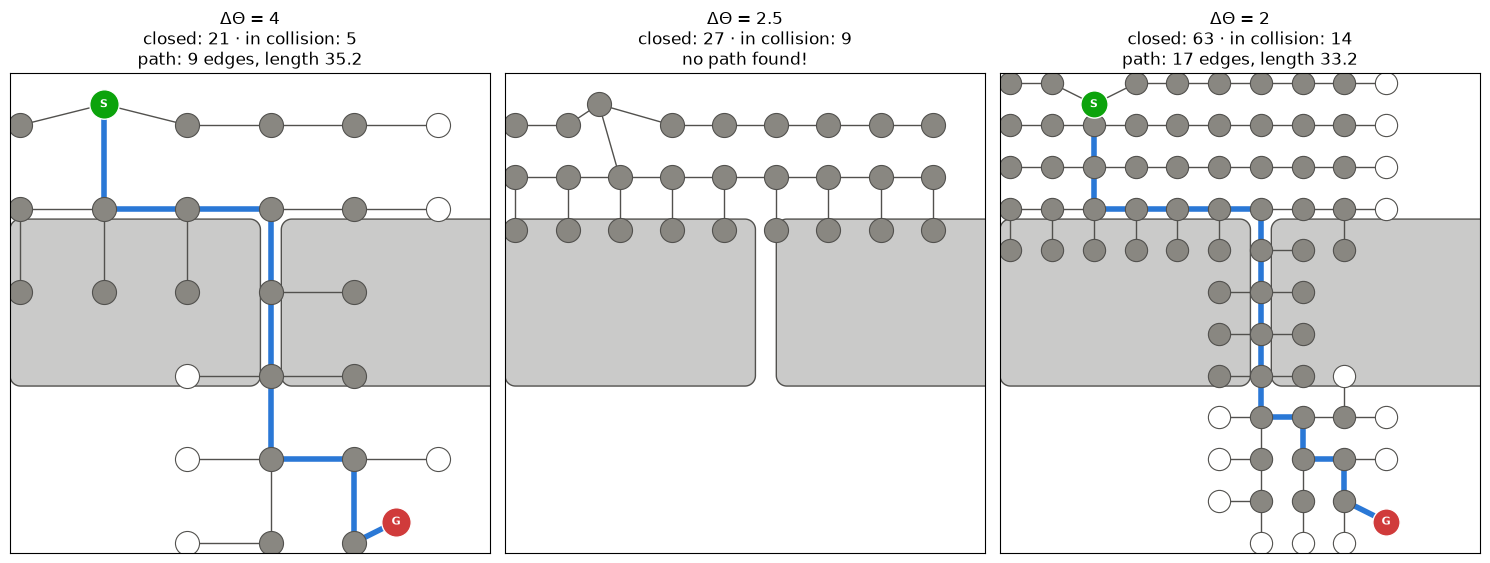

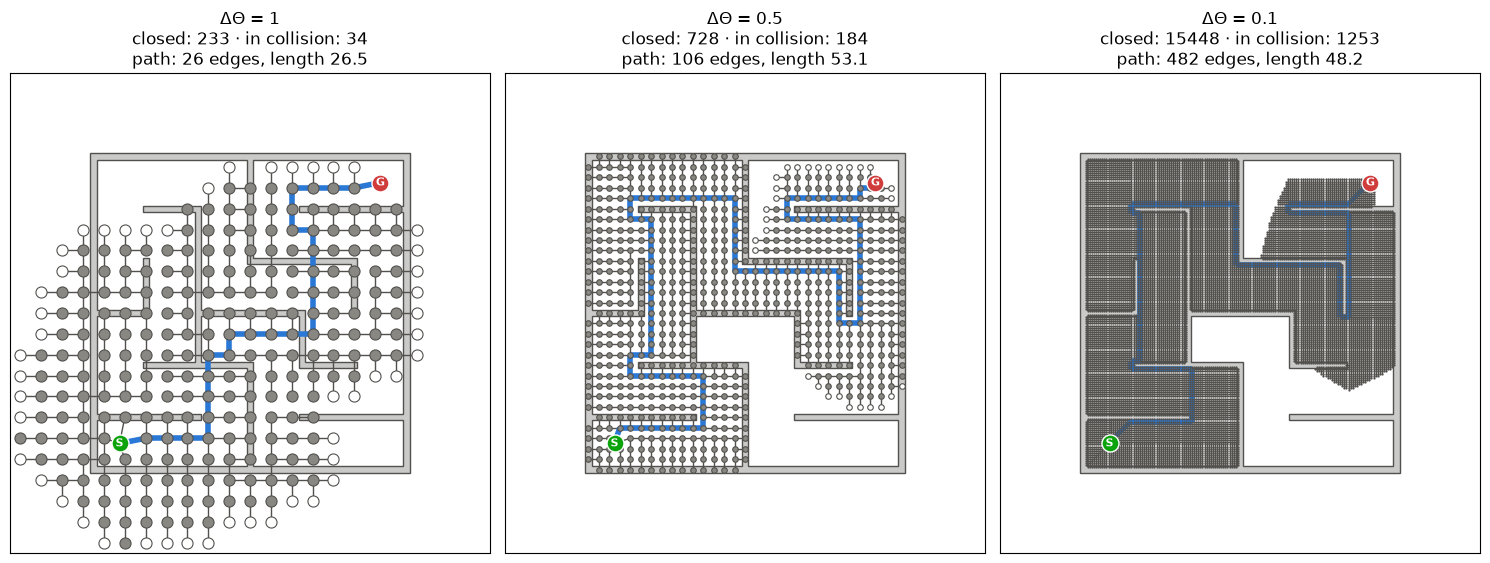

In [156]:
from IPMaze import mazeBenchmark

fatBottleneck = next(benchmark for benchmark in ts.benchList if benchmark.name == "Fat bottleneck")
planAndShow(fatBottleneck.collisionChecker, fatBottleneck.startList, fatBottleneck.goalList,
            [(f"ΔΘ = {d}", {"discretization": d, "maxIterations": 20000}) for d in [4, 2.5, 2]])

maze = mazeBenchmark(rows=6, cols=6, seed=3)
planAndShow(maze.collisionChecker, maze.startList, maze.goalList,
            [(f"ΔΘ = {d}", {"discretization": d, "maxIterations": 20000}) for d in [1, 0.5, 0.1]])

Questions:

* How does the number of closed nodes grow when the step size is halved? What do you expect for a robot with 6 axes?
* Why is there no path through the fat bottleneck with $\Delta\Theta = 2.5$, but with 4 and 2? (Hint: which grid points lie in the passage?)
* Why does the path cross the walls of the maze with $\Delta\Theta = 1$? Why does $\Delta\Theta = 0.5$ work here, although the walls are only 0.3 thick – would it still work, if the maze were shifted by 0.25?
* Extend `_handleNode`, so that only collision-free edges are added (`lineInCollision`). What does this cost?
* Every edge costs 1, whatever $\Delta\Theta_i$ is. How would you choose the step sizes for the axes of a robot? (Hint: how far does the tool move, if axis $i$ moves by $\Delta\Theta_i$? See the slides on hierarchical A*.)